## Adding numbers
* adding: decimal -> binary  
* the half-adder core  
    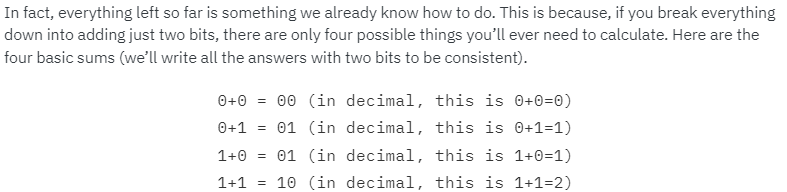
* simple 2-qubit gate: CNOT (classcial XOR gate)
* simple 3-qubit gate: CCNOT (classcial AND gate)
* barrier operations (at this point, just for clean code)


In [8]:
## Import libraries
from qiskit import QuantumCircuit, assemble, Aer
from qiskit.visualization import plot_histogram

The rightmost bit in all four of these answers is completely determined by whether the two bits we are adding are the same.  
To get this part of our solution correct, we need something that can figure out whether two bits are different or not.  
In classicla computers, this is called an XOR gate.  
In quantum computers, the job of the XOR gate is done by the controlled-NOT gate.

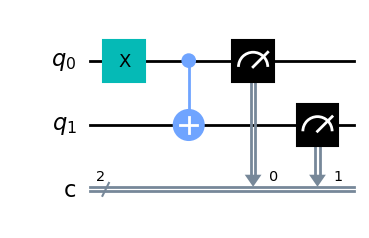

In [9]:
qc = QuantumCircuit(2,2)
qc.x(0)
qc.cx(0,1)
qc.measure(0,0)
qc.measure(1,1)
qc.draw()

For our half adder, we don’t want to overwrite one of our inputs.  
Instead, we want to write the result on a different pair of qubits. For this, we can use two CNOTs.

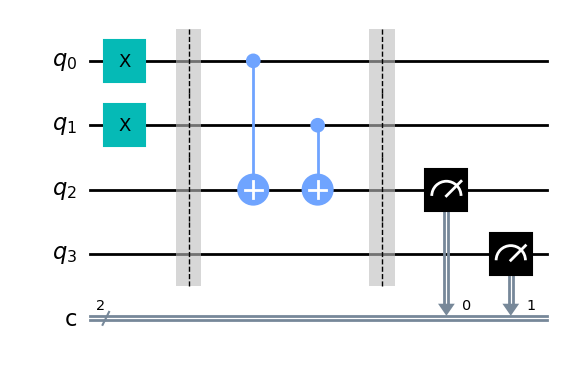

In [10]:
qc_ha = QuantumCircuit(4,2)
# encode inputs in qubits 0 and 1
qc_ha.x(0) # For a=0, remove this line. For a=1, leave it.
qc_ha.x(1) # For b=0, remove this line. For b=1, leave it.
qc_ha.barrier()
# use cnots to write the XOR of the inputs on qubit 2
qc_ha.cx(0,2)
qc_ha.cx(1,2)
qc_ha.barrier()
# extract outputs
qc_ha.measure(2,0) # extract XOR value
qc_ha.measure(3,1)

qc_ha.draw()

We are now halfway to a fully working half adder. We just have the other bit of the output left to do: the one that will live on qubit 3.

If you look again at the four possible sums, you’ll notice that there is only one case for which this is 1 instead of 0: 1+1=10. It happens only when both the bits we are adding are 1.

For this, we need a new gate: like a CNOT but controlled on two qubits instead of just one.  
This will perform a NOT on the target qubit only when both controls are in state 1. This new gate is called the Toffoli.  
It is also known as the controlled-controlled-not gate, which describes its action. 
It has 3-bit inputs and outputs; if the first two bits are both set to 1, it inverts the third bit, otherwise all bits stay the same.

For those of you who are familiar with Boolean logic gates, it is basically an AND gate.

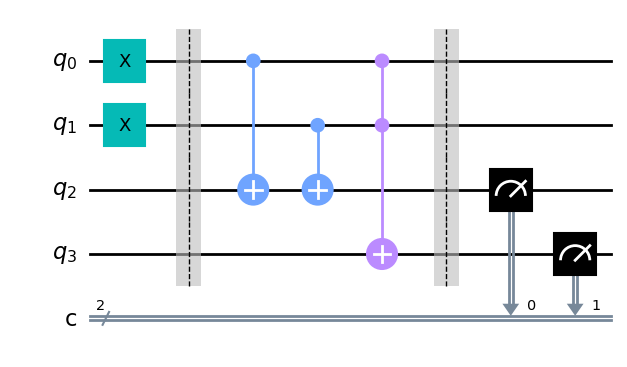

In [87]:
qc_ha = QuantumCircuit(4,2)
# encode inputs in qubits 0 and 1
qc_ha.x(0) # For a=0, remove the this line. For a=1, leave it.
qc_ha.x(1) # For b=0, remove the this line. For b=1, leave it.
qc_ha.barrier()
# use cnots to write the XOR of the inputs on qubit 2
qc_ha.cx(0,2)
qc_ha.cx(1,2)
# use ccx to write the AND of the inputs on qubit 3
qc_ha.ccx(0,1,3)
qc_ha.barrier()
# extract outputs
qc_ha.measure(2,0) # extract XOR value
qc_ha.measure(3,1) # extract AND value

qc_ha.draw()

Let's see what we get.

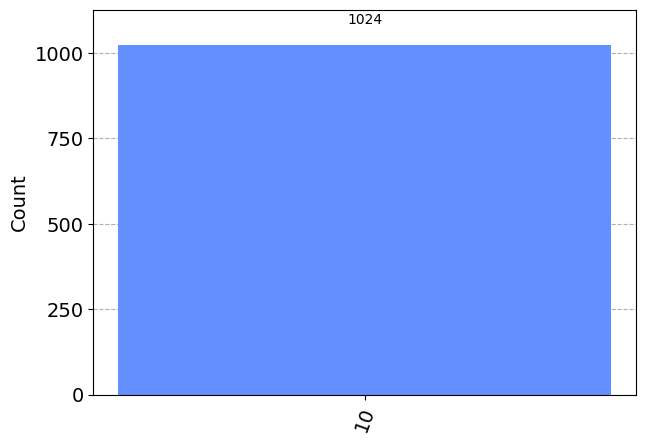

In [14]:
sim = Aer.get_backend('aer_simulator') 

#qobj = assemble(qc_ha)
counts = sim.run(qc_ha).result().get_counts()
plot_histogram(counts)

In [32]:
print(list(counts.keys())[0])

10


### Exercices-1:
* Write a function for automatically adding any two binary numbers of 1-bit lengh passed as str variables.

In [66]:

# encode inputs in qubits 0 and 1
def half_adder(b0,b1):
    qc_ha = QuantumCircuit(4,2)
    
    if b0 == '1':    
        qc_ha.x(0) # For a=0, remove the this line. For a=1, leave it.
    if b1 == '1':
        qc_ha.x(1) # For b=0, remove the this line. For b=1, leave it.
    
    qc_ha.barrier()
    # use cnots to write the XOR of the inputs on qubit 2
    qc_ha.cx(0,2)
    qc_ha.cx(1,2)
    # use ccx to write the AND of the inputs on qubit 3
    qc_ha.ccx(0,1,3)
    qc_ha.barrier()

    # extract outputs
    qc_ha.measure(2,0) # extract XOR value
    qc_ha.measure(3,1) # extract AND value

    #qc_ha.draw()
    
    sim = Aer.get_backend('aer_simulator') 
    counts = sim.run(qc_ha).result().get_counts()
    return list(counts.keys())[0]

b0='0'
b1='1'
res = half_adder(b0,b1)
print(res[0],res[1])

0 1


### Exercice-2:
Modify the previous function to add two bits (len = 1 each) plus a third bit (carrier). Plot the circuit.
hint-1:  use another half-adder to add the carry use another half-adder to add the carry.

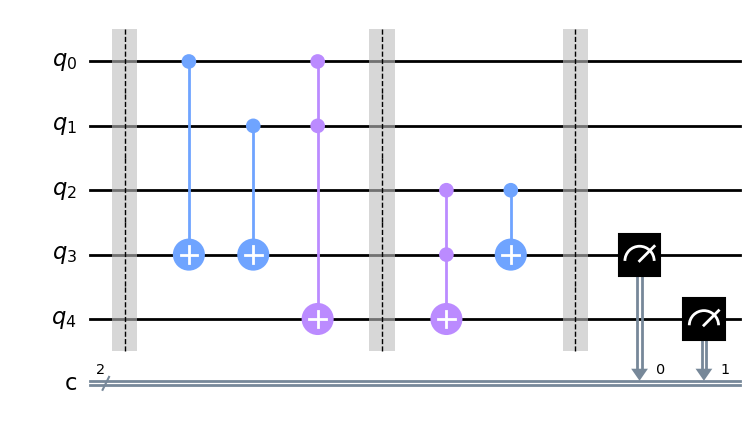

In [175]:
#def full_adder(b0, b1, carry_in):

b0='0'
b1='0'
carry_in = '0'

qc_fa = QuantumCircuit(5, 2)
    
if b0 == '1':    
    qc_fa.x(0) # For a=0, remove this line. For a=1, leave it.
if b1 == '1':
    qc_fa.x(1) # For b=0, remove the this line. For b=1, leave it.
if carry_in == '1':
    qc_fa.x(2) # For carry=0, remove this line. For carry=1, leave it.

qc_fa.barrier()

# use half-adder to add b0 and b1
qc_fa.cx(0,3)
qc_fa.cx(1,3)
qc_fa.ccx(0,1,4)
qc_fa.barrier()

# use another half-adder to add the carry
qc_fa.ccx(2,3,4)
qc_fa.cx(2,3)
#qc_fa.cx(3,2)
qc_fa.barrier()

# extract outputs
qc_fa.measure(3,0) # extract carry-out value
qc_fa.measure(4,1) # extract sum value

qc_fa.draw()



#res = half_adder(b0,b1, carry)
#print(res)

In [176]:
sim = Aer.get_backend('aer_simulator') 
counts = sim.run(qc_fa).result().get_counts()
#return list(counts.keys())[0]

print(list(counts.keys())[0])

00


### Exercice 3:
Write a function that sums any two binary numbers of max_len = 14.
hint-1: use the previous function to add two bit and a carrier.

In [177]:
def full_adder(b0, b1, carry_in):
    qc_fa = QuantumCircuit(5, 2)

    if b0 == '1':    
        qc_fa.x(0) # For a=0, remove this line. For a=1, leave it.
    if b1 == '1':
        qc_fa.x(1) # For b=0, remove the this line. For b=1, leave it.
    if carry_in == '1':
        qc_fa.x(2) # For carry=0, remove this line. For carry=1, leave it.

    qc_fa.barrier()

    # use half-adder to add b0 and b1
    qc_fa.cx(0,3)
    qc_fa.cx(1,3)
    qc_fa.ccx(0,1,4)
    qc_fa.barrier()

    # use another half-adder to add the carry
    qc_fa.ccx(2,3,4)
    qc_fa.cx(2,3)
    #qc_fa.cx(3,2)
    qc_fa.barrier()

    # extract outputs
    qc_fa.measure(3,0) # extract carry-out value
    qc_fa.measure(4,1) # extract sum value

    sim = Aer.get_backend('aer_simulator')
    counts = sim.run(qc_fa).result().get_counts()
    
    return list(counts.keys())[0]


def add_binary_strings(b0, b1):
    # pad binary strings with leading zeros
    max_len = 14
    b0 = b0.zfill(max_len)
    b1 = b1.zfill(max_len)
    #print(b0)

    # initialize variables for storing the sum and carry bits
    sum_bits = []
    carry_bit = '0'
    
    # add the least significant bits using the half adder
    #print(b0[-1], b1[-1],'--' ,carry_bit)
    ha_result = full_adder(b0[-1], b1[-1], carry_bit)
    #print(ha_result, '--' ,carry_bit)
    sum_bits.append(ha_result[1])
    carry_bit = ha_result[0]
    #print(ha_result, '--' ,carry_bit)

    # add the remaining bits using the half adder and the carry bit from the previous addition
    for i in range(2, max_len+1):
        #print(i,b0[-i], b1[-i], carry_bit)
        ha_result = full_adder(b0[-i], b1[-i], carry_bit)
        sum_bits.append(ha_result[1])
        carry_bit = ha_result[0]
        #print(i,ha_result)


    #keep the last acrry bit
    if carry_bit == '1':
        sum_bits.append(carry_bit)
    
    # reverse the order of the sum bits to get the correct binary representation
    sum_bits.reverse()

    return ''.join(sum_bits)



b0 = '10001111111101'#'1010'
b1 = '00011100111110'#'0110'
sum_result = add_binary_strings(b0, b1)
print(f"{b0} + {b1} = {sum_result}")

10001111111101 + 00011100111110 = 10101100111011
